# Data used in the experiments: pilot versus full run

**Study:** Implication-Weighted Data Selection for Financial QA — Protocol v1 (training-free).

This notebook describes the datasets behind every experiment. It covers:

- where the items come from and what was excluded;
- how they are split into the pool, the probe set, the test sets and the demonstrations;
- what the items look like (answer types, operations, lengths, tables, units);
- how they were verified, and the constructed validation negatives;
- the Q3 consequence checks.

Throughout, it compares the **pilot** (100 pool items per dataset, 24 October 2026) with the **full run** (every surviving training item).

**Purely descriptive.** The notebook only *reads* saved pipeline outputs:

- the pilot snapshot in `code/runs/pilot_2026-10-24/data/`;
- the full-run outputs in `code/data/`.

It imports nothing from the pipeline, calls no API, and changes no code, configuration or experiment output. Its only outputs are this notebook and the figures in `notebooks/figures/data_*.pdf`.

## Why the data matter for the thesis

The thesis decomposes an example's value into reliability (R), implication strength (I) and surprisal (S). Its central claim is that **I moderates whether surprising data is useful** (H4). Several properties of the data determine whether that claim can be tested at all, and how its results must be read:

| Data property | Why it matters | Where it is used |
|---|---|---|
| **Verified gold answers** (program execution, derivation re-evaluation) | "Correctness" in E0 (A1) and E3 must come from execution, not from Jev or an LLM | H1, D1, H5 |
| **Answer type** (`arith` vs `lookup`) | D1 is evaluated on `arith` items; Jev is expected to be weakest on derivations | H1, D1 |
| **Operation structure** (FinQA program steps, TAT-QA derivations) | Multi-step derivations are the natural carriers of "implied consequences" and the source of the template Q3 checks | I, Q3 |
| **Pool size per dataset and stratum** | The I × S cells must hold ≥ 100 items per dataset × cell after the R ≥ 0.9 filter | D4, E1-C, E2 |
| **Leakage control between pool and held-out sets** | Influence (G) and demonstration gain (C) would be inflated if pool items duplicated probe or test items | G, C, H2–H6 |
| **Held-out sets** (probe P, in-distribution test, FinanceBench OOD) | P defines the target gradient for G; test sets define accuracy and CBI for C | E1-G, E1-C, E2, E3, H6 |
| **Lengths and token budgets** | Fit of k = 4 demonstrations in the base model's context; length as a possible difficulty confound for I and S | C, D2 |
| **Constructed negatives** | The only items with known false labels, because every original verifies | A1 (H1, D1) |

## 1. Setup

In [1]:
import json
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from scipy import stats

CODE = Path.cwd().parent / "code"
SRC = {"pilot": CODE / "runs" / "pilot_2026-10-24" / "data", "full": CODE / "data"}
FIG_DIR = Path.cwd() / "figures"
FIG_DIR.mkdir(exist_ok=True)
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"pilot": "#d1603d", "full": "#3b6ea5"}
# scipy's exact KS p-value can overflow numerically on large samples; the value is still returned
warnings.filterwarnings("ignore", category=RuntimeWarning, module=r"scipy\.stats")

data_cfg = yaml.safe_load((CODE / "conf" / "data" / "default.yaml").read_text())
pool = {k: pd.read_parquet(v / "pool.parquet") for k, v in SRC.items()}
verified = {k: pd.read_parquet(v / "verified.parquet") for k, v in SRC.items()}
manifest = {k: json.loads((v / "split_manifest.json").read_text()) for k, v in SRC.items()}
exclusions = {k: pd.read_csv(v / "exclusions.csv") for k, v in SRC.items()}
dedup = {k: pd.read_csv(v / "dedup_log.csv") for k, v in SRC.items()}
for k in SRC:
    pool[k] = pool[k].merge(verified[k][["item_id", "verified", "failure_reason"]], on="item_id", how="left")
    print(f"{k:5s}: {len(pool[k]):,} rows in pool.parquet, read from {SRC[k].relative_to(CODE.parent)}")

pilot: 1,860 rows in pool.parquet, read from code/runs/pilot_2026-10-24/data
full : 21,829 rows in pool.parquet, read from code/data


In [2]:
def originals(k):
    p = pool[k]
    return p[(p["split"] == "pool") & ~p["is_derived"]]

def negatives(k):
    p = pool[k]
    return p[p["is_derived"]]

def held_out(k):
    p = pool[k]
    return p[p["split"].isin(["probe", "test", "fixed_demo"])]

## 2. Sources and exclusions

- **Pool:** FinQA train and TAT-QA train.
- **Probe set and fixed demonstrations:** the FinQA and TAT-QA dev splits.
- **In-distribution test sets:** FinQA test and TAT-QA test, using TAT-QA's public test gold file.
- **Out-of-distribution test set:** FinanceBench, restricted to questions with verifiable numeric answers and evidence.

The loaded counts and the exclusions are identical in the pilot and the full run. The pilot differs only in how many pool items it samples afterwards.

In [3]:
loaded = pd.Series(manifest["full"]["loaded"], name="items loaded").to_frame()
loaded.index.name = "dataset/split"
loaded.loc["total"] = loaded.sum()
display(loaded)
assert manifest["pilot"]["loaded"] == manifest["full"]["loaded"]
print("FinanceBench questions removed (non-numeric or without evidence):",
      manifest["full"]["financebench_filtered_non_numeric_or_no_evidence"])

,items loaded
dataset/split,
financebench/test,52
finqa/dev,883
finqa/test,1147
finqa/train,6251
tatqa/dev,1668
tatqa/test,1663
tatqa/train,13215
total,24879


FinanceBench questions removed (non-numeric or without evidence): 98


In [4]:
exc = exclusions["full"].pivot_table(index=["dataset", "source_split"], columns="reason", values="n",
                                     aggfunc="sum", fill_value=0)
exc["total"] = exc.sum(axis=1)
exc.loc[("total", ""), :] = exc.sum()
display(exc.astype(int))
same = exclusions["pilot"].sort_values(list(exclusions["pilot"].columns)).reset_index(drop=True).equals(
    exclusions["full"].sort_values(list(exclusions["full"].columns)).reset_index(drop=True))
print("pilot and full exclusions identical:", same)
leak = dedup["full"]["kind"].value_counts()
print("dedup log:", leak.to_dict(), "| leakage matches (MinHash Jaccard ≥",
      data_cfg["dedup"]["jaccard_threshold"], "between pool and held-out):", int(leak.get("leakage", 0)))

reason                exact_duplicate  token_budget  unverified  total
dataset source_split                                                  
finqa   dev                         7             0           0      7
        test                        9             0           0      9
        train                      57            49           0    106
tatqa   dev                         2            12           6     20
        test                        0             0          12     12
        train                       5            48          38     91
total                              80           109          56    245

pilot and full exclusions identical: True
dedup log: {'exact': 80} | leakage matches (MinHash Jaccard ≥ 0.9 between pool and held-out): 0


**Reading the exclusions.**

- **`exact_duplicate`:** identical items (same text, table and question) within a split; one copy is kept.
- **`token_budget`:** the item is longer than the per-split budget (2,048 tokens for pool, probe and demonstrations; 4,096 for test). Token counts use the base model's (OLMo 3) tokenizer.
- **`unverified`:** the gold answer cannot be reproduced by execution or derivation. These items never enter any split, so every retained original verifies.

The leakage filter compares every pool item with every probe and test item using MinHash (128 permutations, word 5-grams), confirmed by exact Jaccard similarity. **It found no near-duplicates at the 0.9 threshold.** §5 looks at a weaker form of overlap the filter is not designed to catch: shared source contexts.

## 3. Splits: what each experiment draws from

In [5]:
rows = []
for k in ("pilot", "full"):
    p = pool[k]
    for (ds, sp), g in p.groupby(["dataset", "split"]):
        rows.append({"run": k, "dataset": ds, "split": sp, "originals": int((~g["is_derived"]).sum()),
                     "negatives": int(g["is_derived"].sum())})
splits = pd.DataFrame(rows).pivot_table(index=["dataset", "split"], columns="run",
                                        values=["originals", "negatives"], fill_value=0).astype(int)
display(splits)
for sp in ("probe", "test", "fixed_demo"):
    a = set(pool["pilot"].loc[pool["pilot"]["split"] == sp, "item_id"])
    b = set(pool["full"].loc[pool["full"]["split"] == sp, "item_id"])
    print(f"{sp:10s}: pilot {len(a):5d}, full {len(b):5d}, identical: {a == b}")
po, fo = set(originals("pilot")["item_id"]), set(originals("full")["item_id"])
print(f"pilot pool originals are a subset of the full pool: {po <= fo} ({len(po)} of {len(fo):,}, {len(po)/len(fo):.2%})")
pn, fn = set(negatives("pilot")["item_id"]), set(negatives("full")["item_id"])
print(f"negatives shared between pilot and full: {len(pn & fn)} of {len(pn)} pilot negatives")

negatives       originals      
run                          full pilot      full pilot
dataset      split                                     
financebench test               0     0        52    52
finqa        fixed_demo         0     0         4     4
             pool             319    50      6145   100
             probe              0     0       250   250
             test               0     0       500   500
tatqa        fixed_demo         0     0         4     4
             pool             681    50     13124   100
             probe              0     0       250   250
             test               0     0       500   500

probe     : pilot   500, full   500, identical: True
test      : pilot  1052, full  1052, identical: True
fixed_demo: pilot     8, full     8, identical: True
pilot pool originals are a subset of the full pool: True (200 of 19,269, 1.04%)
negatives shared between pilot and full: 3 of 100 pilot negatives


| Split | Size (per dataset) | Role in the protocol |
|---|---|---|
| **pool** | pilot 100; full: every surviving training item | The items being valued: scored by Jev (R, I) and the base model (S); G is computed per item; selection conditions draw demonstrations from it |
| **probe** | 250 | Probe set P (500 items in total, as the protocol specifies): the mean probe gradient defines G |
| **fixed_demo** | 4 | Fixed demonstrations for the ICL-reducible-loss comparator (Spec 3) |
| **test** | 500 (+ 52 FinanceBench) | In-distribution test sets for C, accuracy and CBI; FinanceBench is the OOD test |

**The held-out sets are identical in the pilot and the full run.** Probe, test and demonstration items are drawn first, with fixed seeds, before the pool is sized. Any pilot result that involves P or the test sets therefore carries over directly. The pilot pool is a stratified 1% subsample of the full pool.

**The negatives were drawn separately at each size**, so only 3 of the pilot's 100 recur among the full run's 1,000. Pilot and full A1 estimates are therefore based on mostly different negatives.

## 4. Composition of the pool

The pool is stratified only by dataset and `answer_type`. In the pilot, each dataset's 100 items follow that dataset's training composition. The full pool *is* the training composition.

Two classifications are used:

- **`answer_type`** is the protocol's two-way split. `arith` means the answer is computed; `lookup` means it is read off the table or text.
- **`source_answer_type`** is the finer label: FinQA's final program operation, or TAT-QA's answer type.

In [6]:
def share_table(col, frames):
    out = {}
    for k, f in frames.items():
        out[(k, "n")] = f.groupby(["dataset", col]).size()
        out[(k, "%")] = f.groupby(["dataset", col]).size() / f.groupby("dataset").size() * 100
    return pd.DataFrame(out).fillna(0)

o = {k: originals(k) for k in ("pilot", "full")}
display(share_table("answer_type", o).round(1))
display(share_table("source_answer_type", o).round(1))

pilot        full      
                        n     %     n     %
dataset answer_type                        
finqa   arith          97  97.0  5962  97.0
        lookup          3   3.0   183   3.0
tatqa   arith          44  44.0  5788  44.1
        lookup         56  56.0  7336  55.9

pilot        full      
                               n     %     n     %
dataset source_answer_type                        
finqa   add                  7.0   7.0   486   7.9
        divide              71.0  71.0  3980  64.8
        greater              2.0   2.0   122   2.0
        multiply             4.0   4.0   301   4.9
        subtract            13.0  13.0  1073  17.5
        table_average        2.0   2.0    89   1.4
        table_max            1.0   1.0    46   0.7
        table_min            0.0   0.0    25   0.4
        table_sum            0.0   0.0    23   0.4
tatqa   arithmetic          43.0  43.0  5484  41.8
        count                1.0   1.0   304   2.3
        multi-span          14.0  14.0  1633  12.4
        span                42.0  42.0  5703  43.5

In [7]:
def chi2_vs_full(col):
    res = []
    for ds in ("finqa", "tatqa"):
        f = o["full"][o["full"]["dataset"] == ds][col].value_counts()
        p = o["pilot"][o["pilot"]["dataset"] == ds][col].value_counts().reindex(f.index, fill_value=0)
        expected = f / f.sum() * p.sum()
        keep = expected >= 1
        chi = stats.chisquare(p[keep], expected[keep] * p[keep].sum() / expected[keep].sum())
        tvd = 0.5 * (p / p.sum() - f / f.sum()).abs().sum()
        res.append({"dataset": ds, "variable": col, "total variation distance": tvd,
                    "χ² goodness-of-fit p": chi.pvalue, "categories": int(keep.sum())})
    return res

display(pd.DataFrame(chi2_vs_full("answer_type") + chi2_vs_full("source_answer_type")).set_index(["dataset", "variable"]))

,,total variation distance,χ² goodness-of-fit p,categories
dataset,variable,,,
finqa,answer_type,2.197e-04,0.990,2
tatqa,answer_type,1.024e-03,0.984,2
finqa,source_answer_type,7.050e-02,0.820,6
tatqa,source_answer_type,2.771e-02,0.795,4


**Representativeness of the pilot.** The pilot was stratified on `answer_type` only, so it matches the full pool on that variable by construction. The finer `source_answer_type` was not controlled. The total variation distance shows how far the pilot drifts on it: the share of items that would have to change category to match the full pool.

Pilot results broken down by operation type (for example the perturbation types in the pilot Jev analysis) should be read with this drift and the small cell sizes in mind.

**Dataset balance differs by design.** The pilot takes 100 items from each dataset, so its pool is 50% FinQA. The full pool is 32% FinQA (6,145 of 19,269), and the negatives follow the same proportions. Within each dataset the answer-type mix matches. Pooled across datasets, however, the pilot has more arithmetic items (70.5% vs 61%) and more FinQA, the dataset Jev finds harder.

**Consequence for the paper:** pooled pilot statistics (an overall AUROC, ρ(R, I), the share with R ≥ 0.9) are weighted towards FinQA. Full-run values can differ from the pilot's simply because of this reweighting. Per-dataset values are the comparable ones.

## 5. Item structure: operations, lengths, tables and units

These features describe *what kind of reasoning* an item asks for. They are candidate confounds for I and S (D2), and they explain where template Q3 checks are possible.

**FinQA program steps** is the number of operations in the gold program, for example `subtract(a, b), divide(#0, b)` has two steps. **TAT-QA derivation operators** counts the arithmetic operators in the gold derivation of arithmetic items.

In [8]:
OPS = re.compile(r"\b(add|subtract|multiply|divide|exp|greater|table_\w+)\(")

def features(f):
    f = f.copy()
    f["program_steps"] = f["program"].map(lambda s: len(OPS.findall(s)) if isinstance(s, str) and s else np.nan)
    f["derivation_ops"] = f["derivation"].map(
        lambda s: len(re.findall(r"(?<=[\d)\s])[+\-*/×÷](?=[\s\d(.$])", s)) if isinstance(s, str) and s else np.nan)
    f["table_rows"] = f["table"].map(lambda t: len(t) if t is not None else 0)
    f["table_cols"] = f["table"].map(lambda t: max((len(r) for r in t), default=0) if t is not None else 0)
    f["paragraphs"] = f["context_text"].map(lambda t: len(t) if t is not None else 0)
    f["scale"] = f["scale"].fillna("").replace("", "none")
    f["percent_answer"] = f["gold_answer"].str.contains("%|percent", case=False, regex=True)
    f["negative_answer"] = f["gold_answer"].str.strip().str.match(r"^[-−(]")
    return f

of = {k: features(o[k]) for k in ("pilot", "full")}
fq = {k: v[v["dataset"] == "finqa"] for k, v in of.items()}
display(pd.DataFrame({k: v["program_steps"].value_counts(normalize=True).sort_index() * 100 for k, v in fq.items()})
        .fillna(0).round(1).rename_axis("FinQA program steps (% of originals)"))
ta = {k: v[(v["dataset"] == "tatqa") & (v["source_answer_type"] == "arithmetic")] for k, v in of.items()}
display(pd.DataFrame({k: v["derivation_ops"].clip(upper=5).value_counts(normalize=True).sort_index() * 100
                      for k, v in ta.items()}).fillna(0).round(1)
        .rename_axis("TAT-QA arithmetic: derivation operators (5 = 5+), % of items"))

,pilot,full
FinQA program steps (% of originals),,
1.0,57.0,59.6
2.0,34.0,32.2
3.0,7.0,5.1
4.0,1.0,1.5
5.0,1.0,1.4
6.0,0.0,0.1


,pilot,full
"TAT-QA arithmetic: derivation operators (5 = 5+), % of items",,
0.0,0.0,0.9
1.0,44.2,52.4
2.0,46.5,39.5
3.0,7.0,5.0
4.0,0.0,0.6
5.0,2.3,1.4


In [9]:
num_cols = ["qa_tokens", "context_chars", "paragraphs", "table_rows", "table_cols"]
rows = []
for ds in ("finqa", "tatqa"):
    for c in num_cols:
        a = of["pilot"].loc[of["pilot"]["dataset"] == ds, c]
        b = of["full"].loc[of["full"]["dataset"] == ds, c]
        smd = (a.mean() - b.mean()) / b.std(ddof=1) if b.std(ddof=1) > 0 else 0.0
        rows.append({"dataset": ds, "feature": c, "pilot median": a.median(), "full median": b.median(),
                     "full p5": b.quantile(.05), "full p95": b.quantile(.95), "full max": b.max(),
                     "SMD (pilot − full)": smd, "KS p": stats.ks_2samp(a, b, method="asymp").pvalue})
display(pd.DataFrame(rows).set_index(["dataset", "feature"]))

pilot median  full median  full p5  full p95  full max  \
dataset feature                                                                 
finqa   qa_tokens             930.5        899.0    436.0    1374.0      2044   
        context_chars        4022.0       3894.0   1429.0    6030.0      9980   
        paragraphs             23.0         22.0      7.0      39.0       490   
        table_rows              5.0          6.0      3.0      10.0        20   
        table_cols              4.0          4.0      2.0       7.0        11   
tatqa   qa_tokens             476.5        415.0    166.0    1013.0      1908   
        context_chars        1528.5       1379.0    400.0    4015.0      8695   
        paragraphs              4.0          4.0      2.0      10.0        29   
        table_rows              8.0          8.0      5.0      19.0        29   
        table_cols              4.0          4.0      3.0       6.0         9   

                       SMD (pilot − full)   KS p  
dataset feature                                   
finqa   qa_tokens                   0.101  0.376  
        context_chars               0.164  0.115  
        paragraphs                 -0.044  0.930  
        table_rows                 -0.050  0.568  
        table_cols                 -0.008  1.000  
tatqa   qa_tokens                   0.252  0.139  
        context_chars               0.197  0.213  
        paragraphs                  0.083  0.672  
        table_rows                  0.121  0.832  
        table_cols                  0.102  0.985

**Findings.**
- **Length by dataset.** FinQA items are about twice as long as TAT-QA items: median 899 vs 415 tokens. FinQA has many short paragraphs and a small table; TAT-QA has fewer paragraphs and a larger table.
- **Operation depth.** About 60% of FinQA programs have one operation and about a third have two. Multi-step derivations (3+ steps) are a small minority (about 8%), and TAT-QA arithmetic is similar. Most "implied consequences" are therefore one or two inferential steps away, which matches the thesis's motivating example.
- **Pilot representativeness.** The pilot is slightly longer than the full pool (standardised mean differences 0.1–0.25), but no distribution differs significantly (all KS p > 0.1).

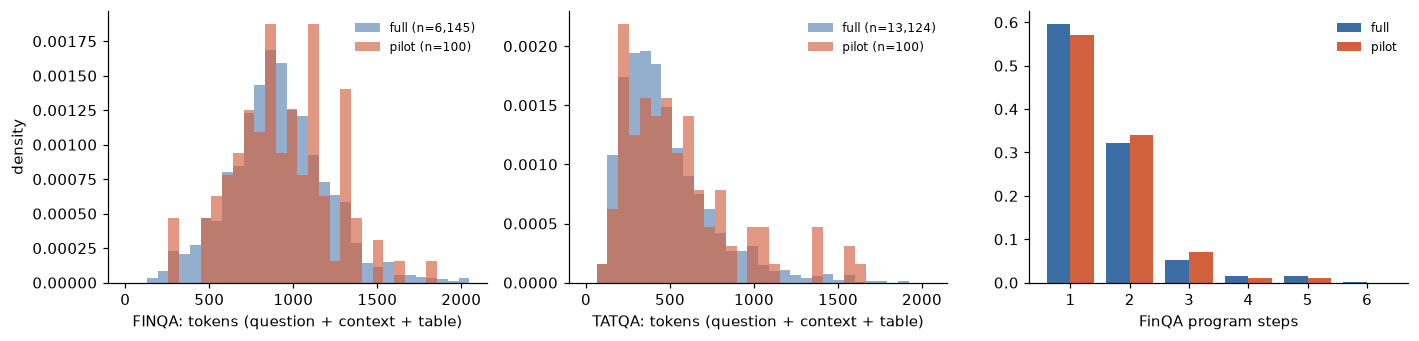

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, ds in zip(axes[:2], ("finqa", "tatqa")):
    for k in ("full", "pilot"):
        v = of[k].loc[of[k]["dataset"] == ds, "qa_tokens"]
        ax.hist(v, bins=np.linspace(0, 2048, 33), density=True, alpha=0.55 if k == "full" else 0.65,
                color=COLORS[k], label=f"{k} (n={len(v):,})")
    ax.set_xlabel(f"{ds.upper()}: tokens (question + context + table)")
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("density")
steps = pd.DataFrame({k: v["program_steps"].value_counts(normalize=True).sort_index() for k, v in fq.items()}).fillna(0)
x = np.arange(len(steps))
axes[2].bar(x - 0.2, steps["full"], 0.4, color=COLORS["full"], label="full")
axes[2].bar(x + 0.2, steps["pilot"], 0.4, color=COLORS["pilot"], label="pilot")
axes[2].set_xticks(x, steps.index.astype(int))
axes[2].set_xlabel("FinQA program steps")
axes[2].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "data_lengths_and_steps.pdf", bbox_inches="tight")
plt.show()

In [11]:
units = []
for k in ("pilot", "full"):
    g = of[k].groupby("dataset")
    units.append(pd.DataFrame({"run": k, "percent answers": g["percent_answer"].mean() * 100,
                               "negative answers": g["negative_answer"].mean() * 100,
                               "with a table": g["table_rows"].apply(lambda s: (s > 0).mean() * 100)}))
display(pd.concat(units).reset_index().set_index(["dataset", "run"]).round(1))
display(pd.crosstab(of["full"]["dataset"], of["full"]["scale"], normalize="index").mul(100).round(1)
        .rename_axis(index="full pool: scale of the answer (% of originals)"))

,,percent answers,negative answers,with a table
dataset,run,,,
finqa,pilot,60.0,13.0,100.0
tatqa,pilot,24.0,11.0,100.0
finqa,full,56.2,11.6,100.0
tatqa,full,18.2,10.9,100.0


scale,billion,million,none,percent,thousand
full pool: scale of the answer (% of originals),,,,,
finqa,0.0,0.0,100.0,0.0,0.0
tatqa,0.1,16.3,49.0,15.9,18.7


**Shared source contexts.** The leakage filter removes pool items that are near-duplicates of a probe or test *item*: question, context and table together. It does not remove pool items that share a *report page or table* with a held-out item but ask a different question.

FinQA and TAT-QA attach several questions to one context, but the official train, dev and test splits are separate reports. So such overlap should be rare. The check below counts pool originals whose table and text are identical to some held-out item's.

In [12]:
def ctx_key(f):
    return f.apply(lambda r: json.dumps([r["dataset"], list(map(list, r["table"])) if r["table"] is not None else [],
                                         list(r["context_text"]) if r["context_text"] is not None else []]), axis=1)

ho = held_out("full")
ho_keys = set(ctx_key(ho))
fk = ctx_key(o["full"])
shared = fk.isin(ho_keys)
print(f"full pool originals sharing their exact context with a probe/test/demo item: {int(shared.sum())} of {len(fk):,} "
      f"({shared.mean():.2%})")
display(o["full"].loc[shared].groupby("dataset").size().rename("pool items with a shared context").to_frame())
ctx_per_item = fk.value_counts()
print(f"distinct contexts in the full pool: {len(ctx_per_item):,} for {len(fk):,} items "
      f"(mean {len(fk) / len(ctx_per_item):.2f} questions per context; max {ctx_per_item.max()})")

full pool originals sharing their exact context with a probe/test/demo item: 0 of 19,269 (0.00%)


,pool items with a shared context
dataset,


distinct contexts in the full pool: 4,287 for 19,269 items (mean 4.49 questions per context; max 8)


**Findings.** No pool item shares its exact context with any probe, test or demonstration item. So there is no context-level leakage, and G and C cannot be inflated by the model seeing a held-out item's source during selection.

Within the pool, however, the 19,269 items come from only 4,287 distinct contexts: about 4.5 questions per context, up to 8.

**Questions per context** matters for the statistics. Items that share a context are not independent: an influence or demonstration effect may be a property of the report, not of the question. Spec 5's bootstrap over probe items, and the dataset fixed effects, do not cluster by context. This is worth a sentence in the limitations, or a context-clustered robustness check.

## 6. Verified correctness

Correctness for E0 and E3 comes from execution:

- FinQA programs are re-executed with the official executor.
- TAT-QA derivations are re-evaluated, with an evaluator that accepts accounting negatives.
- TAT-QA spans are checked for presence in the context, ignoring case and quotes.
- Counts are checked as counts.

FinanceBench items have no program and are not verified; they are used only as test items.

In [13]:
ver = []
for k in ("pilot", "full"):
    p = pool[k]
    for (split, deriv), g in p.groupby(["split", "is_derived"]):
        ver.append({"run": k, "split": split, "item": "negative" if deriv else "original", "n": len(g),
                    "verified": int((g["verified"] == True).sum()),
                    "not verified": int((g["verified"] == False).sum()),
                    "not applicable (FinanceBench)": int(g["verified"].isna().sum())})
display(pd.DataFrame(ver).set_index(["run", "split", "item"]))

n  verified  not verified  \
run   split      item                                      
pilot fixed_demo original      8         8             0   
      pool       original    200       200             0   
                 negative    100        14            86   
      probe      original    500       500             0   
      test       original   1052      1000             0   
full  fixed_demo original      8         8             0   
      pool       original  19269     19269             0   
                 negative   1000       225           775   
      probe      original    500       500             0   
      test       original   1052      1000             0   

                           not applicable (FinanceBench)  
run   split      item                                     
pilot fixed_demo original                              0  
      pool       original                              0  
                 negative                              0  
      probe      original                              0  
      test       original                             52  
full  fixed_demo original                              0  
      pool       original                              0  
                 negative                              0  
      probe      original                              0  
      test       original                             52

**Every original in every split verifies.** Items whose gold answer cannot be reproduced were excluded in §2: 56 in total across all splits, all TAT-QA. A1's reliability analysis therefore cannot use naturally false labels, which is why Spec 1 constructs negatives.

The verified rate is itself a result worth reporting. It supports the claim that, on these datasets, "reliability" in the thesis's sense is mostly *not* about the gold label. That is exactly why the protocol tests whether Jev's R adds anything beyond execution (D1).

## 7. Validation negatives

Negatives are pool items with a wrong gold answer. They are stratified by dataset × `answer_type`; there are 100 in the pilot and 1,000 in the full run (Spec 1). The wrong answer is built in one of four ways:

- **numeric factor:** multiply the gold value by 0.5, 0.8, 1.25 or 2;
- **sign flip:** for direction-type items;
- **boolean flip:** for yes/no items;
- **span swap:** for lookup items, a different span of the same length class from the same context.

Every wrong answer is confirmed with `answers_match` not to equal the gold answer.

In [14]:
neg = {k: negatives(k).assign(kind=lambda f: f["perturbation"].str.replace(r":.*", "", regex=True)) for k in ("pilot", "full")}
display(pd.concat({k: v.groupby(["dataset", "answer_type"]).size() for k, v in neg.items()}, axis=1)
        .assign(**{"full: % of negatives": lambda f: f["full"] / f["full"].sum() * 100,
                   "full pool: % of originals": o["full"].groupby(["dataset", "answer_type"]).size()
                   / len(o["full"]) * 100}).round(1))
display(pd.concat({k: v["perturbation"].value_counts() for k, v in neg.items()}, axis=1).fillna(0).astype(int))

pilot  full  full: % of negatives  \
dataset answer_type                                      
finqa   arith           49   309                  30.9   
        lookup           1    10                   1.0   
tatqa   arith           22   300                  30.0   
        lookup          28   381                  38.1   

                     full pool: % of originals  
dataset answer_type                             
finqa   arith                             30.9  
        lookup                             0.9  
tatqa   arith                             30.0  
        lookup                            38.1

,pilot,full
perturbation,,
factor:0.5,21,145
factor:2,20,160
factor:1.25,16,149
sign_flip,16,181
span_swap,14,222
factor:0.8,13,131
bool_flip,0,7
table_value,0,5


In [15]:
nv = pd.concat({k: v.groupby(["kind", "source_answer_type"])["verified"].agg(["size", "sum"]) for k, v in neg.items()})
nv.columns = ["negatives", "pass verification"]
display(nv.astype(int))
fullneg = neg["full"]
span_ok = fullneg[(fullneg["kind"] == "span_swap")]["verified"].mean()
print(f"span-swap negatives that pass span verification (full run): {span_ok:.1%}")

negatives  pass verification
      kind        source_answer_type                              
pilot factor      add                         3                  0
                  arithmetic                 13                  0
                  divide                     37                  0
                  multi-span                  1                  0
                  multiply                    2                  0
                  span                       13                  0
                  table_average               1                  0
      sign_flip   arithmetic                  9                  0
                  subtract                    7                  0
      span_swap   multi-span                  6                  6
                  span                        8                  8
full  bool_flip   greater                     7                  0
      factor      add                        29                  0
                  arithmetic                163                  0
                  count                      17                  0
                  divide                    194                  0
                  multi-span                  1                  0
                  multiply                   13                  0
                  span                      158                  3
                  table_average               3                  0
                  table_max                   4                  0
                  table_min                   2                  0
                  table_sum                   1                  0
      sign_flip   arithmetic                118                  0
                  subtract                   63                  0
      span_swap   multi-span                 89                 89
                  span                      133                133
      table_value arithmetic                  2                  0
                  divide                      1                  0
                  subtract                    2                  0

span-swap negatives that pass span verification (full run): 100.0%


**Reading the negatives.**

- **Stratification:** the negatives' composition mirrors the pool's dataset × `answer_type` shares, so A1's overall AUROC is weighted like the pool.
- **Perturbation mix:** numeric factors dominate because arithmetic items dominate. The subtle factors (0.8 and 1.25) are the closest stand-in for plausible wrong answers.
- **Span swaps pass verification.** All span-swap negatives still "verify" (100%), because span verification only checks that the answer appears in the context. A few factor-perturbed numeric spans also pass, when the new number happens to appear in the context. Their labels are wrong with respect to the gold answer, and A1 labels them as negatives by construction.

**For the paper:** span verification is a necessary, not sufficient, correctness check. And the E3 "corrupted" variant can rely on numeric perturbations being caught by execution, but span corruptions would not be.

## 8. Q3 consequence checks

Each pool item and negative gets one check statement that must hold whenever its stated answer holds. Checks come from templates over the gold program or derivation where one applies (direction, ordering, total, magnitude), and otherwise from Qwen3-235B-A22B-Instruct-2507 under a frozen prompt.

The checks are not yet human-validated. The full-run checks appear here once the q3 stage has finished writing them; until then, only the pilot's are shown.

In [16]:
q3 = {"pilot": pd.read_parquet(SRC["pilot"] / "q3_checks.parquet")}
full_q3 = pd.read_parquet(SRC["full"] / "q3_checks.parquet")
targets_full = set(pool["full"].loc[pool["full"]["split"] == "pool", "item_id"])
if len(full_q3) > len(q3["pilot"]) and set(full_q3["item_id"]) <= targets_full:
    q3["full"] = full_q3
    print(f"full-run Q3 checks: {len(full_q3):,} for {len(targets_full):,} targets")
else:
    print("full-run Q3 checks not written yet (q3 stage still running): showing the pilot only")
dropped = {k: pd.read_csv(SRC[k] / "q3_dropped.csv") for k in q3}
for k, c in q3.items():
    items_k = pool[k][["item_id", "dataset", "answer_type", "is_derived"]]
    q3[k] = c.merge(items_k, on="item_id")
    print(f"{k}: {len(c):,} checks, {len(dropped[k])} items dropped after two failed LLM attempts")
display(pd.concat({k: pd.crosstab([c["dataset"], c["answer_type"]], c["source"], normalize="index").mul(100)
                   for k, c in q3.items()}, axis=1).round(1).rename_axis(columns=["run", "check source (%)"]))
display(pd.concat({k: c["check_type"].value_counts(normalize=True).mul(100) for k, c in q3.items()}, axis=1).round(1)
        .rename_axis("check type (% of checks)"))
display(pd.concat({k: c["template_op"].value_counts() for k, c in q3.items()}, axis=1).fillna(0).astype(int)
        .rename_axis("template used"))

full-run Q3 checks: 20,255 for 20,269 targets
pilot: 299 checks, 1 items dropped after two failed LLM attempts
full: 20,255 checks, 14 items dropped after two failed LLM attempts


run                  pilot            full         
check source (%)       llm template    llm template
dataset answer_type                                
finqa   arith          1.4     98.6    1.1     98.9
        lookup         0.0    100.0    1.0     99.0
tatqa   arith          1.5     98.5    6.9     93.1
        lookup       100.0      0.0  100.0      0.0

,pilot,full
check type (% of checks),,
ordering,61.2,54.6
direction,22.1,28.5
total,11.0,10.9
magnitude,5.4,5.4
unit,0.3,0.6


,pilot,full
template used,,
divide,143,7147
subtract,41,3467
add,16,786
multiply,7,335
table_average,3,92
greater,2,129
table_max,1,50
table_min,0,27
table_sum,0,22


**Reading the checks.**

- **Source follows answer type.** Template checks cover most arithmetic items (FinQA almost entirely), while lookup items rely on the LLM. Any difference in Q3 between template and LLM checks is therefore confounded with answer type. The pilot Jev analysis found the same.
- **Mostly ordering checks.** Most checks state an ordering ("the answer is greater than …") or a direction of change. These are the "one or two inferential steps" consequences the thesis has in mind, but in a narrow form. The paper should describe Q3 as measuring *entailment of a simple, verifiable consequence*, not open-ended implication.

## 9. Context fit for the demonstration proxy (C)

Proxy C prepends k = 4 demonstrations from the pool to a test item, reduced to k = 2 where the prompt would exceed the length budget. The base model is OLMo 3 7B Instruct, with a 65,536-token context (YaRN) against the protocol's 16,384-token minimum.

The estimate below gives a conservative prompt length: four pool items at the 95th percentile of length, plus a test item at its 99th percentile.

In [17]:
budget = data_cfg["token_budget"]
po95 = o["full"].groupby("dataset")["qa_tokens"].quantile(0.95)
te = pool["full"][pool["full"]["split"] == "test"]
te99 = te.groupby("dataset")["qa_tokens"].quantile(0.99)
fit = pd.DataFrame({"pool p95 tokens": po95, "test p99 tokens": te99})
fit["k=4 prompt estimate"] = 4 * fit["pool p95 tokens"] + fit["test p99 tokens"]
fit["share of 65,536"] = fit["k=4 prompt estimate"] / 65536
fit["share of 16,384 (protocol minimum)"] = fit["k=4 prompt estimate"] / 16384
display(fit.round(3))
print("token budgets (exclusion thresholds):", budget)

,pool p95 tokens,test p99 tokens,k=4 prompt estimate,"share of 65,536","share of 16,384 (protocol minimum)"
dataset,,,,,
financebench,NaN,2058.84,NaN,NaN,NaN
finqa,1374.0,1904.24,7400.24,0.113,0.452
tatqa,1013.0,1558.14,5610.14,0.086,0.342


token budgets (exclusion thresholds): {'pool': 2048, 'test': 4096}


**Findings.** Even the conservative k = 4 prompt (about 7,400 tokens for FinQA, 5,600 for TAT-QA) uses under half of the protocol's 16,384-token minimum and about 11% of OLMo 3's context. The protocol's fallback to k = 2 should never be needed for FinQA or TAT-QA, so C is computed with the same k everywhere.

FinanceBench has no pool items of its own; its test items (99th percentile about 2,060 tokens) use the same pool demonstrations, and also fit.

## 10. Summary for the paper

The cell below prints a data paragraph and a summary table, with numbers filled in from this notebook.

In [18]:
fo_ = o["full"]
n_fq, n_tq = (fo_["dataset"] == "finqa").sum(), (fo_["dataset"] == "tatqa").sum()
arith_share = (fo_["answer_type"] == "arith").mean()
fq_lookup = ((fo_["dataset"] == "finqa") & (fo_["answer_type"] == "lookup")).sum()
excl_total = int(exclusions["full"]["n"].sum())
summary = pd.DataFrame([
    ["pool originals", len(o["pilot"]), len(fo_)],
    ["  FinQA / TAT-QA", f"{(o['pilot']['dataset'] == 'finqa').sum()} / {(o['pilot']['dataset'] == 'tatqa').sum()}", f"{n_fq:,} / {n_tq:,}"],
    ["  arith share", f"{(o['pilot']['answer_type'] == 'arith').mean():.1%}", f"{arith_share:.1%}"],
    ["validation negatives", len(neg["pilot"]), len(neg["full"])],
    ["probe items (P)", (pool["pilot"]["split"] == "probe").sum(), (pool["full"]["split"] == "probe").sum()],
    ["in-distribution test items", ((pool["pilot"]["split"] == "test") & (pool["pilot"]["dataset"] != "financebench")).sum(),
     ((pool["full"]["split"] == "test") & (pool["full"]["dataset"] != "financebench")).sum()],
    ["FinanceBench OOD test items", (pool["pilot"]["dataset"] == "financebench").sum(), (pool["full"]["dataset"] == "financebench").sum()],
    ["exclusions (all splits)", int(exclusions["pilot"]["n"].sum()), excl_total],
    ["leakage removals", int((dedup["pilot"]["kind"] == "leakage").sum()), int((dedup["full"]["kind"] == "leakage").sum())],
    ["originals verified", f"{(o['pilot']['verified'] == True).mean():.0%}", f"{(fo_['verified'] == True).mean():.0%}"],
], columns=["", "pilot", "full"]).set_index("")
display(summary)

text = f'''
DATA. The pool consists of the FinQA and TAT-QA training splits after exact deduplication, removal of
items over a 2,048-token budget (4,096 for test items; OLMo 3 tokenizer), and removal of items whose gold answer could not be
reproduced by executing the FinQA program or re-evaluating the TAT-QA derivation ({excl_total} items
removed across all splits). This leaves {len(fo_):,} items ({n_fq:,} FinQA, {n_tq:,} TAT-QA;
{arith_share:.0%} arithmetic), every one with a verified gold answer. A MinHash near-duplicate filter
(Jaccard ≥ 0.9 on word 5-grams) against the held-out sets removed no items. The probe set has 500 dev
items and the in-distribution test sets 500 test items per dataset, stratified by answer type; 52
FinanceBench questions with verifiable numeric answers form the out-of-distribution test set. For the
reliability analysis we construct 1,000 validation negatives by perturbing the gold answer of pool items
(numeric factors, sign flips, yes/no flips and span swaps), stratified by dataset and answer type. A
200-item pilot pool, a stratified subsample of the full pool, shares the same probe and test sets.
'''
print(text)

,pilot,full
,,
pool originals,200,19269
FinQA / TAT-QA,100 / 100,"6,145 / 13,124"
arith share,70.5%,61.0%
validation negatives,100,1000
probe items (P),500,500
in-distribution test items,1000,1000
FinanceBench OOD test items,52,52
exclusions (all splits),245,245
leakage removals,0,0



DATA. The pool consists of the FinQA and TAT-QA training splits after exact deduplication, removal of
items over a 2,048-token budget (4,096 for test items; OLMo 3 tokenizer), and removal of items whose gold answer could not be
reproduced by executing the FinQA program or re-evaluating the TAT-QA derivation (245 items
removed across all splits). This leaves 19,269 items (6,145 FinQA, 13,124 TAT-QA;
61% arithmetic), every one with a verified gold answer. A MinHash near-duplicate filter
(Jaccard ≥ 0.9 on word 5-grams) against the held-out sets removed no items. The probe set has 500 dev
items and the in-distribution test sets 500 test items per dataset, stratified by answer type; 52
FinanceBench questions with verifiable numeric answers form the out-of-distribution test set. For the
reliability analysis we construct 1,000 validation negatives by perturbing the gold answer of pool items
(numeric factors, sign flips, yes/no flips and span swaps), stratified by dataset and answer type. A
2

### Caveats for the paper

1. **FinQA lookup is tiny:** 183 items, about 3% of FinQA. Any FinQA-specific lookup estimate, or a per-dataset cell that requires lookup items, rests on few items.
2. **The OOD test set is small:** 52 FinanceBench items, almost all "metrics-generated". OOD effects will have wide intervals and should be reported descriptively.
3. **Questions cluster within contexts** (§5). Several questions share a report page or table, and the protocol's statistics treat items as independent. Consider a context-clustered robustness check.
4. **All originals verify,** so reliability is evaluated only on constructed negatives (§6–7). Span-swap negatives pass span verification.
5. **Q3 checks are narrow and their source is confounded with answer type** (§8). They are not yet human-validated.
6. **The pilot is a 1% subsample with the same held-out sets, but balanced 50/50 across datasets.** The full pool is 32/68 FinQA/TAT-QA. Within each dataset the answer-type mix matches by design; finer operation types drift, and pilot cells below that level are small. Compare pilot and full results per dataset, not pooled (§4).